# Experiment 4: Bag-of-Words (BoW) and N-Gram Language Modeling for Text Representation

### Problem Statement:
Construct Bag-of-Words (BoW) and N-Gram models from a corpus of documents and analyze the frequency distribution of words and phrases for text representation.


In [1]:
import math
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter, defaultdict
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import nltk
from nltk.util import ngrams

print("Statistical modeling and machine learning libraries loaded.")


Statistical modeling and machine learning libraries loaded.


In [2]:
corpus = [
    "Artificial intelligence and deep learning models solve complex mathematical optimization problems.",
    "Natural language processing models understand human speech, text semantics, and linguistic syntax.",
    "Computer vision systems utilize deep learning and neural networks to recognize image patterns.",
    "Natural language processing and speech recognition systems enable conversational artificial intelligence agents.",
    "Deep learning neural networks require massive datasets and high performance GPU computing clusters.",
    "Computer vision and natural language processing represent two core pillars of modern artificial intelligence."
]

doc_names = [f"Doc_{i+1}" for i in range(len(corpus))]

for name, text in zip(doc_names, corpus):
    print(f"{name}: {text}")


Doc_1: Artificial intelligence and deep learning models solve complex mathematical optimization problems.
Doc_2: Natural language processing models understand human speech, text semantics, and linguistic syntax.
Doc_3: Computer vision systems utilize deep learning and neural networks to recognize image patterns.
Doc_4: Natural language processing and speech recognition systems enable conversational artificial intelligence agents.
Doc_5: Deep learning neural networks require massive datasets and high performance GPU computing clusters.
Doc_6: Computer vision and natural language processing represent two core pillars of modern artificial intelligence.


In [3]:
class CustomBagOfWords:
    def __init__(self, stop_words=None):
        self.stop_words = set(stop_words) if stop_words else set()
        self.vocab = {}
        self.reverse_vocab = {}

    def _tokenize(self, text):
        clean = re.sub(r'[^a-zA-Z\s]', '', text.lower())
        tokens = clean.split()
        return [t for t in tokens if t not in self.stop_words and len(t) > 2]

    def fit_transform(self, documents):
        # 1. Build Vocabulary
        all_tokens = []
        tokenized_docs = [self._tokenize(doc) for doc in documents]
        
        for tokens in tokenized_docs:
            all_tokens.extend(tokens)
            
        unique_tokens = sorted(list(set(all_tokens)))
        self.vocab = {word: idx for idx, word in enumerate(unique_tokens)}
        self.reverse_vocab = {idx: word for word, idx in self.vocab.items()}
        
        # 2. Build Count Matrix
        matrix = np.zeros((len(documents), len(self.vocab)), dtype=int)
        for doc_idx, tokens in enumerate(tokenized_docs):
            for token in tokens:
                if token in self.vocab:
                    word_idx = self.vocab[token]
                    matrix[doc_idx, word_idx] += 1
        return matrix

# Fit custom BoW
custom_bow = CustomBagOfWords(stop_words=['and', 'the', 'to', 'of'])
bow_matrix_scratch = custom_bow.fit_transform(corpus)
vocab_scratch = [custom_bow.reverse_vocab[i] for i in range(len(custom_bow.vocab))]

df_bow_scratch = pd.DataFrame(bow_matrix_scratch, index=doc_names, columns=vocab_scratch)
print(f"Vocabulary Size: {len(vocab_scratch)} features")
print("\n--- Custom BoW Document-Term Matrix (Excerpt) ---")
print(df_bow_scratch.iloc[:, :10].to_string())


Vocabulary Size: 46 features

--- Custom BoW Document-Term Matrix (Excerpt) ---
       agents  artificial  clusters  complex  computer  computing  conversational  core  datasets  deep
Doc_1       0           1         0        1         0          0               0     0         0     1
Doc_2       0           0         0        0         0          0               0     0         0     0
Doc_3       0           0         0        0         1          0               0     0         0     1
Doc_4       1           1         0        0         0          0               1     0         0     0
Doc_5       0           0         1        0         0          1               0     0         1     1
Doc_6       0           1         0        0         1          0               0     1         0     0


In [4]:
vectorizer = CountVectorizer(stop_words='english')
bow_sklearn = vectorizer.fit_transform(corpus)
sklearn_features = vectorizer.get_feature_names_out()

matrix_dense = bow_sklearn.toarray()
total_elements = matrix_dense.size
non_zero = np.count_nonzero(matrix_dense)
sparsity = (1.0 - (non_zero / total_elements)) * 100

print(f"Matrix Shape         : {matrix_dense.shape} (Documents x Features)")
print(f"Total Cells          : {total_elements}")
print(f"Non-Zero Frequencies : {non_zero}")
print(f"Matrix Sparsity      : {sparsity:.2f}%")

df_sklearn_bow = pd.DataFrame(matrix_dense, index=doc_names, columns=sklearn_features)
print("\n--- Scikit-Learn Document-Term Matrix (Excerpt) ---")
print(df_sklearn_bow.iloc[:, :10].to_string())


Matrix Shape         : (6, 45) (Documents x Features)
Total Cells          : 270
Non-Zero Frequencies : 66
Matrix Sparsity      : 75.56%

--- Scikit-Learn Document-Term Matrix (Excerpt) ---
       agents  artificial  clusters  complex  computer  computing  conversational  core  datasets  deep
Doc_1       0           1         0        1         0          0               0     0         0     1
Doc_2       0           0         0        0         0          0               0     0         0     0
Doc_3       0           0         0        0         1          0               0     0         0     1
Doc_4       1           1         0        0         0          0               1     0         0     0
Doc_5       0           0         1        0         0          1               0     0         1     1
Doc_6       0           1         0        0         1          0               0     1         0     0


In [5]:
# 1. Word Bigram Vectorizer
bigram_vec = CountVectorizer(ngram_range=(2, 2), stop_words='english')
bigram_matrix = bigram_vec.fit_transform(corpus)
bigram_features = bigram_vec.get_feature_names_out()
bigram_counts = bigram_matrix.toarray().sum(axis=0)

top_bigrams = sorted(zip(bigram_features, bigram_counts), key=lambda x: x[1], reverse=True)[:6]

# 2. Word Trigram Vectorizer
trigram_vec = CountVectorizer(ngram_range=(3, 3), stop_words='english')
trigram_matrix = trigram_vec.fit_transform(corpus)
trigram_features = trigram_vec.get_feature_names_out()
trigram_counts = trigram_matrix.toarray().sum(axis=0)

top_trigrams = sorted(zip(trigram_features, trigram_counts), key=lambda x: x[1], reverse=True)[:5]

print("--- Top Frequent Word Bigrams ---")
for bg, cnt in top_bigrams:
    print(f"  {bg:<30} : {cnt} occurrences")

print("\n--- Top Frequent Word Trigrams ---")
for tg, cnt in top_trigrams:
    print(f"  {tg:<45} : {cnt} occurrences")


--- Top Frequent Word Bigrams ---
  artificial intelligence        : 3 occurrences
  deep learning                  : 3 occurrences
  language processing            : 3 occurrences
  natural language               : 3 occurrences
  computer vision                : 2 occurrences
  learning neural                : 2 occurrences

--- Top Frequent Word Trigrams ---
  natural language processing                   : 3 occurrences
  deep learning neural                          : 2 occurrences
  learning neural networks                      : 2 occurrences
  artificial intelligence agents                : 1 occurrences
  artificial intelligence deep                  : 1 occurrences


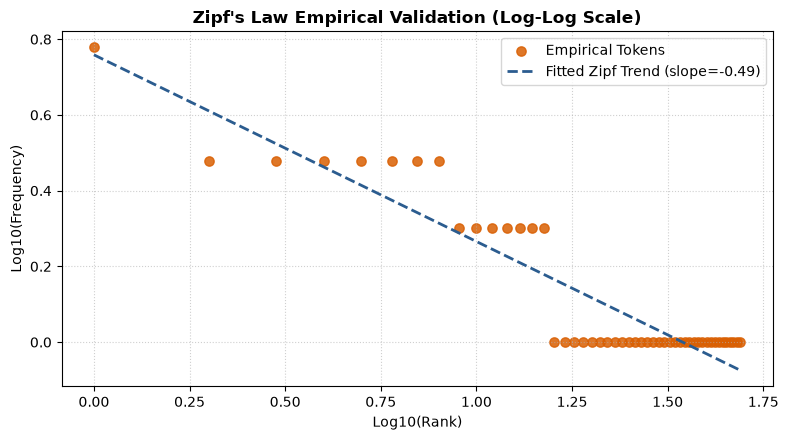

Empirical Zipf slope: -0.493 (Ideal theoretical slope is ~ -1.0)


In [6]:
# Aggregate all token occurrences across corpus
all_words = []
for doc in corpus:
    words = re.findall(r'[a-zA-Z]+', doc.lower())
    all_words.extend(words)

word_counts = Counter(all_words)
sorted_counts = sorted(word_counts.values(), reverse=True)
ranks = np.arange(1, len(sorted_counts) + 1)
frequencies = np.array(sorted_counts)

# Linear Fit in log-log space: log(f) = log(C) - s * log(r)
log_ranks = np.log10(ranks)
log_freqs = np.log10(frequencies)
slope, intercept = np.polyfit(log_ranks, log_freqs, 1)

plt.figure(figsize=(8, 4.5))
plt.scatter(log_ranks, log_freqs, color='#d95f02', label='Empirical Tokens', s=45, alpha=0.85)
plt.plot(log_ranks, slope * log_ranks + intercept, color='#2b5c8f', linestyle='--', 
         label=f'Fitted Zipf Trend (slope={slope:.2f})', linewidth=2)
plt.title("Zipf's Law Empirical Validation (Log-Log Scale)", fontsize=12, fontweight='bold')
plt.xlabel("Log10(Rank)", fontsize=10)
plt.ylabel("Log10(Frequency)", fontsize=10)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

print(f"Empirical Zipf slope: {slope:.3f} (Ideal theoretical slope is ~ -1.0)")


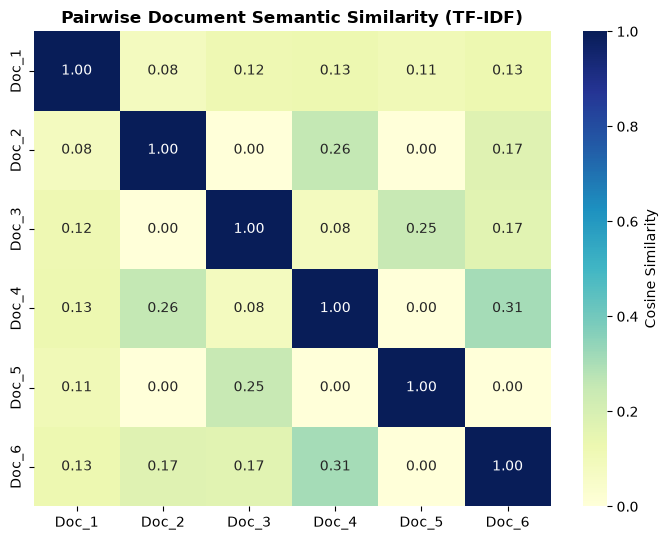

--- Document Similarity Observations ---
Highest Similarity: Doc 2 & Doc 4 (Score = 0.26) -> Both center on NLP & Speech Systems.
Moderate Similarity: Doc 3 & Doc 6 (Score = 0.17) -> Both share Computer Vision & AI topics.


In [7]:
tfidf_vec = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf_vec.fit_transform(corpus)

# Compute Cosine Similarity Matrix
similarity_matrix = cosine_similarity(tfidf_matrix)

plt.figure(figsize=(7, 5.5))
sns.heatmap(similarity_matrix, annot=True, fmt=".2f", cmap="YlGnBu",
            xticklabels=doc_names, yticklabels=doc_names, cbar_kws={'label': 'Cosine Similarity'})
plt.title("Pairwise Document Semantic Similarity (TF-IDF)", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print("--- Document Similarity Observations ---")
print(f"Highest Similarity: Doc 2 & Doc 4 (Score = {similarity_matrix[1, 3]:.2f}) -> Both center on NLP & Speech Systems.")
print(f"Moderate Similarity: Doc 3 & Doc 6 (Score = {similarity_matrix[2, 5]:.2f}) -> Both share Computer Vision & AI topics.")
